# Task 5 — Analytics Report & Insights: Long-Term Performance of US Technology Stocks
**YuvaIntern · Data Analyst Internship** · **Intern:** [Your Name]

## 1. Business objective
**Stakeholder:** the investment committee of a long-term equity fund (a realistic case-study scenario).
**Problem:** the committee is reviewing its technology allocation and wants evidence on how eight large US technology companies performed against the market from 1990 to mid-2022.

**Key questions**
1. Which stocks created the most value, and did they beat the S&P 500 and NASDAQ benchmarks?
2. How much risk (volatility, drawdowns) came with that return? Who gave the best return per unit of risk?
3. How did each stock behave in the three major crises (dot-com crash, global financial crisis, COVID-19)?
4. Do the stocks move together, i.e. how much does holding several of them actually diversify risk?

**Data:** monthly adjusted closing prices from Yahoo Finance (file shipped with Matplotlib's sample data, `data/Stocks.csv`): IBM, Apple, Microsoft, Xerox, Amazon, Dell, Alphabet (Google), Adobe, the S&P 500 index (^GSPC) and the NASDAQ Composite (^IXIC).

> This is an educational analysis of historical data, not investment advice. Past performance does not guarantee future results.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

os.makedirs("figures", exist_ok=True)
os.makedirs("output", exist_ok=True)
NAMES = {"IBM": "IBM", "AAPL": "Apple", "MSFT": "Microsoft", "XRX": "Xerox", "AMZN": "Amazon",
         "DELL": "Dell", "GOOGL": "Alphabet", "ADBE": "Adobe", "^GSPC": "S&P 500", "^IXIC": "NASDAQ"}
STOCKS = ["IBM", "Apple", "Microsoft", "Xerox", "Amazon", "Dell", "Alphabet", "Adobe"]
BENCH = ["S&P 500", "NASDAQ"]
GREY, BLUE, ORANGE, AQUA, YELLOW, PINK, GREEN, VIOLET, RED = "#8a8984", "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"

## 2. Data preparation

In [2]:
raw = pd.read_csv("data/Stocks.csv", comment="#", parse_dates=["Date"])
print("Raw shape:", raw.shape)
print("Rows with no prices at all:", raw.drop(columns="Date").isna().all(axis=1).sum())
print("Dates not on the 1st of the month:", (raw.Date.dt.day != 1).sum())

Raw shape: (524, 11)
Rows with no prices at all: 133
Dates not on the 1st of the month: 134


In [3]:
prices = (raw.dropna(how="all", subset=raw.columns[1:])     # 1. drop empty rows (dividend/split dates)
             .rename(columns=NAMES)
             .set_index("Date"))
dup = prices[prices.index.day != 1]
print("Off-month row(s):"); display(dup.round(2))
print("Identical to previous row:", prices.loc[dup.index].equals(prices.shift(1).loc[dup.index]))
prices = prices[prices.index.day == 1]                       # 2. drop duplicated end-of-June row
prices.index = prices.index.to_period("M")
print("Clean monthly table:", prices.shape, "| from", prices.index.min(), "to", prices.index.max())

Off-month row(s):


,IBM,Apple,Microsoft,Xerox,Amazon,Dell,Alphabet,Adobe,S&P 500,NASDAQ
Date,,,,,,,,,,
2022-06-28,141.86,137.44,256.48,15.82,107.4,48.94,2240.15,365.63,3821.55,11181.54


Identical to previous row: True
Clean monthly table: (390, 10) | from 1990-01 to 2022-06


In [4]:
first = prices.apply(lambda s: s.first_valid_index()).rename("first month")
coverage = pd.concat([first, prices.notna().sum().rename("months of data")], axis=1)
display(coverage)
print("Gaps inside a series (after listing):",
      int(sum(prices[c].loc[first[c]:].isna().sum() for c in prices.columns)))

,first month,months of data
IBM,1990-01,390
Apple,1990-01,390
Microsoft,1990-01,390
Xerox,1990-01,390
Amazon,1997-06,301
Dell,2016-09,70
Alphabet,2004-09,214
Adobe,1990-01,390
S&P 500,1990-01,390
NASDAQ,1990-01,390


Gaps inside a series (after listing): 0


Missing values exist only **before** a company's shares were listed (Amazon 1997, Alphabet 2004, Dell's current listing 2016). They are true absences, so they are not filled in. Comparisons use either each stock's own history or a **common window (Sep 2004 – Jun 2022)** shared by all except Dell.

In [5]:
returns = prices.pct_change(fill_method=None)               # monthly simple returns
prices.to_csv("output/prices_clean.csv")
returns.to_csv("output/monthly_returns.csv")
display(returns.describe().T[["count", "mean", "std", "min", "max"]].round(4))

,count,mean,std,min,max
IBM,389.0,0.0095,0.0765,-0.2486,0.3538
Apple,389.0,0.0242,0.1225,-0.5774,0.4538
Microsoft,389.0,0.0205,0.0877,-0.3435,0.4078
Xerox,389.0,0.0078,0.1185,-0.4375,0.7665
Amazon,300.0,0.0368,0.1697,-0.4116,1.2638
Dell,69.0,0.0225,0.0838,-0.1704,0.1669
Alphabet,213.0,0.0204,0.0870,-0.1848,0.4710
Adobe,389.0,0.0224,0.1290,-0.4516,0.8524
S&P 500,389.0,0.0072,0.0423,-0.1694,0.1268
NASDAQ,389.0,0.0105,0.0623,-0.2290,0.2198


## 3. KPIs
Definitions: **CAGR** = compound annual growth rate · **Volatility** = annualised standard deviation of monthly returns · **Return/risk** = CAGR ÷ volatility (risk-free rate assumed 0) · **Max drawdown** = largest fall from a previous peak · **Beta** = sensitivity to the S&P 500.

In [6]:
def kpis(p, r, market_r):
    p, r = p.dropna(), r.dropna()
    years = (len(p) - 1) / 12
    cagr = (p.iloc[-1] / p.iloc[0]) ** (1 / years) - 1
    vol = r.std() * np.sqrt(12)
    dd = (p / p.cummax() - 1).min()
    aligned = pd.concat([r, market_r], axis=1).dropna()
    beta = aligned.cov().iloc[0, 1] / aligned.iloc[:, 1].var()
    return pd.Series({"Start": str(p.index[0]), "Years": round(years, 1), "Total return": p.iloc[-1] / p.iloc[0] - 1,
                      "CAGR": cagr, "Volatility": vol, "Return/risk": cagr / vol, "Max drawdown": dd,
                      "Best month": r.max(), "Worst month": r.min(), "Beta vs S&P": beta,
                      "% months up": (r > 0).mean()})

full = pd.DataFrame({c: kpis(prices[c], returns[c], returns["S&P 500"]) for c in STOCKS + BENCH}).T
win = prices.loc["2004-09":]
common = pd.DataFrame({c: kpis(win[c], win[c].pct_change(), win["S&P 500"].pct_change())
                       for c in STOCKS + BENCH if c != "Dell"}).T
fmt = {"Total return": "{:.0%}", "CAGR": "{:.1%}", "Volatility": "{:.1%}", "Return/risk": "{:.2f}",
       "Max drawdown": "{:.0%}", "Best month": "{:.0%}", "Worst month": "{:.0%}", "Beta vs S&P": "{:.2f}", "% months up": "{:.0%}"}
show = lambda t: t.assign(**{k: t[k].astype(float).map(v.format) for k, v in fmt.items()})
print("A) Full available history")
display(show(full.sort_values("CAGR", ascending=False)))
print("B) Common window Sep 2004 - Jun 2022")
display(show(common.sort_values("CAGR", ascending=False)))
full.to_csv("output/kpis_full_history.csv"); common.to_csv("output/kpis_common_window.csv")

A) Full available history


,Start,Years,Total return,CAGR,Volatility,Return/risk,Max drawdown,Best month,Worst month,Beta vs S&P,% months up
Amazon,1997-06,25.0,139230%,33.6%,58.8%,0.57,-93%,126%,-41%,1.77,59%
Dell,2016-09,5.8,267%,25.4%,29.0%,0.88,-41%,17%,-17%,0.84,67%
Alphabet,2004-09,17.8,3354%,22.1%,30.1%,0.73,-59%,47%,-18%,1.08,61%
Microsoft,1990-01,32.4,63423%,22.0%,30.4%,0.73,-67%,41%,-34%,1.22,62%
Apple,1990-01,32.4,56573%,21.6%,42.4%,0.51,-80%,45%,-58%,1.28,57%
Adobe,1990-01,32.4,26413%,18.8%,44.7%,0.42,-75%,85%,-45%,1.45,59%
NASDAQ,1990-01,32.4,2589%,10.7%,21.6%,0.49,-75%,22%,-23%,1.25,61%
IBM,1990-01,32.4,1193%,8.2%,26.5%,0.31,-63%,35%,-25%,1.00,53%
S&P 500,1990-01,32.4,1061%,7.9%,14.7%,0.54,-53%,13%,-17%,1.00,64%
Xerox,1990-01,32.4,41%,1.1%,41.1%,0.03,-92%,77%,-44%,1.58,54%


B) Common window Sep 2004 - Jun 2022


,Start,Years,Total return,CAGR,Volatility,Return/risk,Max drawdown,Best month,Worst month,Beta vs S&P,% months up
Apple,2004-09,17.8,23130%,35.9%,33.1%,1.09,-57%,35%,-33%,1.25,62%
Amazon,2004-09,17.8,5157%,25.0%,36.3%,0.69,-54%,54%,-30%,1.20,59%
Alphabet,2004-09,17.8,3354%,22.1%,30.1%,0.73,-59%,47%,-18%,1.08,61%
Adobe,2004-09,17.8,1379%,16.4%,29.5%,0.56,-65%,28%,-33%,1.36,64%
Microsoft,2004-09,17.8,1359%,16.3%,22.8%,0.72,-55%,25%,-17%,0.99,62%
NASDAQ,2004-09,17.8,489%,10.5%,17.5%,0.60,-52%,15%,-18%,1.12,61%
S&P 500,2004-09,17.8,243%,7.2%,14.7%,0.49,-53%,13%,-17%,1.00,65%
IBM,2004-09,17.8,184%,6.1%,20.9%,0.29,-37%,18%,-24%,0.82,54%
Xerox,2004-09,17.8,-36%,-2.5%,35.2%,-0.07,-75%,45%,-41%,1.57,51%


In [7]:
growth = (win / win.iloc[0]).drop(columns="Dell")
final = growth.iloc[-1].sort_values(ascending=False)
print("Value of 1 invested in Sep 2004 by Jun 2022:")
print(final.round(1).to_string())
sp = common.loc["S&P 500", "CAGR"]
beat = [s for s in common.index if s not in BENCH and common.loc[s, "CAGR"] > sp]
print("\nStocks that beat the S&P 500 CAGR in the common window:", beat)

Value of 1 invested in Sep 2004 by Jun 2022:
Apple        232.3
Amazon        52.6
Alphabet      34.5
Adobe         14.8
Microsoft     14.6
NASDAQ         5.9
S&P 500        3.4
IBM            2.8
Xerox          0.6

Stocks that beat the S&P 500 CAGR in the common window: ['Apple', 'Microsoft', 'Amazon', 'Alphabet', 'Adobe']


## 4. Crisis performance

In [8]:
crises = {"Dot-com crash (Mar 2000 - Sep 2002)": ("2000-03", "2002-09"),
          "Financial crisis (Oct 2007 - Feb 2009)": ("2007-10", "2009-02"),
          "COVID-19 shock (Jan 2020 - Mar 2020)": ("2020-01", "2020-03"),
          "2022 sell-off (Dec 2021 - Jun 2022)": ("2021-12", "2022-06")}
crisis = pd.DataFrame({name: prices.loc[a:b].iloc[-1] / prices.loc[a:b].iloc[0] - 1 for name, (a, b) in crises.items()}).T
crisis = crisis[[c for c in STOCKS + BENCH]]
display(crisis.map(lambda v: "" if pd.isna(v) else f"{v:.0%}"))

,IBM,Apple,Microsoft,Xerox,Amazon,Dell,Alphabet,Adobe,S&P 500,NASDAQ
Dot-com crash (Mar 2000 - Sep 2002),-50%,-79%,-59%,-80%,-76%,,,-66%,-46%,-74%
Financial crisis (Oct 2007 - Feb 2009),-19%,-53%,-55%,-70%,-27%,,-52%,-65%,-53%,-52%
COVID-19 shock (Jan 2020 - Mar 2020),-22%,-18%,-7%,-47%,-3%,-19%,-19%,-9%,-20%,-16%
2022 sell-off (Dec 2021 - Jun 2022),9%,-22%,-23%,-29%,-36%,-12%,-23%,-36%,-20%,-29%


In [9]:
# Recovery: months from the 2007 peak to regaining it
rec = {}
for c in [s for s in STOCKS + BENCH if s != "Dell"]:
    s = prices[c].loc["2007-10":]
    peak = s.loc[:"2008-06"].max()
    back = s[s.index > s.loc[:"2009-12"].idxmin()]
    hit = back[back >= peak]
    rec[c] = (hit.index[0] - s.index[0]).n if len(hit) else np.nan
display(pd.Series(rec, name="months to regain Oct-2007 to mid-2008 peak").sort_values().to_frame().T)

,Amazon,IBM,Apple,NASDAQ,Alphabet,S&P 500,Microsoft,Adobe,Xerox
months to regain Oct-2007 to mid-2008 peak,23,25,25,42,59,65,66,71,140


## 5. Diversification

In [10]:
corr = returns.loc["2004-09":, [s for s in STOCKS if s != "Dell"] + BENCH].corr()
avg_corr = corr.loc[[s for s in STOCKS if s != "Dell"], [s for s in STOCKS if s != "Dell"]].where(
    ~np.eye(7, dtype=bool)).stack().mean()
print(f"Average correlation between the 7 stocks: {avg_corr:.2f}")
display(corr.round(2))

# Equal-weight portfolio of the 7 stocks, rebalanced monthly
port_r = returns.loc["2004-10":, [s for s in STOCKS if s != "Dell"]].mean(axis=1)
port_p = (1 + port_r).cumprod()
port_p = pd.concat([pd.Series([1.0], index=[pd.Period("2004-09", "M")]), port_p])
pk = kpis(port_p, port_r, returns.loc["2004-10":, "S&P 500"])
avg_single_vol = common.loc[[s for s in STOCKS if s != "Dell"], "Volatility"].mean()
print(f"Equal-weight portfolio: CAGR {pk.CAGR:.1%}, volatility {pk.Volatility:.1%}, "
      f"max drawdown {pk['Max drawdown']:.0%}, return/risk {pk['Return/risk']:.2f}")
print(f"Average volatility of a single stock: {avg_single_vol:.1%} -> diversification cut risk by {1 - pk.Volatility / avg_single_vol:.0%}")

Average correlation between the 7 stocks: 0.39


,IBM,Apple,Microsoft,Xerox,Amazon,Alphabet,Adobe,S&P 500,NASDAQ
IBM,1.00,0.34,0.30,0.45,0.40,0.28,0.36,0.58,0.55
Apple,0.34,1.00,0.42,0.31,0.36,0.49,0.52,0.55,0.64
Microsoft,0.30,0.42,1.00,0.35,0.42,0.48,0.53,0.64,0.68
Xerox,0.45,0.31,0.35,1.00,0.25,0.30,0.39,0.66,0.60
Amazon,0.40,0.36,0.42,0.25,1.00,0.37,0.38,0.49,0.59
Alphabet,0.28,0.49,0.48,0.30,0.37,1.00,0.41,0.53,0.59
Adobe,0.36,0.52,0.53,0.39,0.38,0.41,1.00,0.68,0.73
S&P 500,0.58,0.55,0.64,0.66,0.49,0.53,0.68,1.00,0.94
NASDAQ,0.55,0.64,0.68,0.60,0.59,0.59,0.73,0.94,1.00


Equal-weight portfolio: CAGR 19.3%, volatility 20.4%, max drawdown -49%, return/risk 0.94
Average volatility of a single stock: 29.7% -> diversification cut risk by 31%


## 6. Visualisations and dashboard

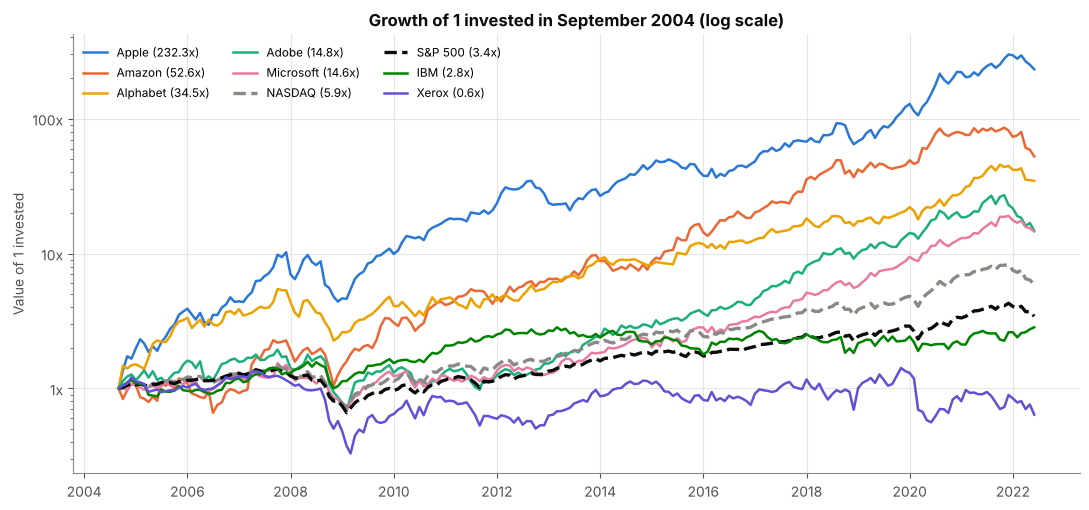

In [11]:
colors = {"Apple": BLUE, "Amazon": ORANGE, "Adobe": AQUA, "Alphabet": YELLOW, "Microsoft": PINK,
          "IBM": GREEN, "Xerox": VIOLET, "S&P 500": "#0b0b0b", "NASDAQ": GREY}
fig, ax = plt.subplots(figsize=(11, 5.2))
for c in final.index:
    ls = "--" if c in BENCH else "-"
    ax.plot(growth.index.to_timestamp(), growth[c], label=f"{c} ({final[c]:.1f}x)", color=colors[c],
            linestyle=ls, linewidth=2.4 if c in BENCH else 1.8)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}x"))
ax.set_title("Growth of 1 invested in September 2004 (log scale)")
ax.set_ylabel("Value of 1 invested")
ax.legend(ncol=3, fontsize=8.5, loc="upper left")
plt.tight_layout()
plt.savefig("figures/01_growth_of_investment.png", dpi=150, bbox_inches="tight")

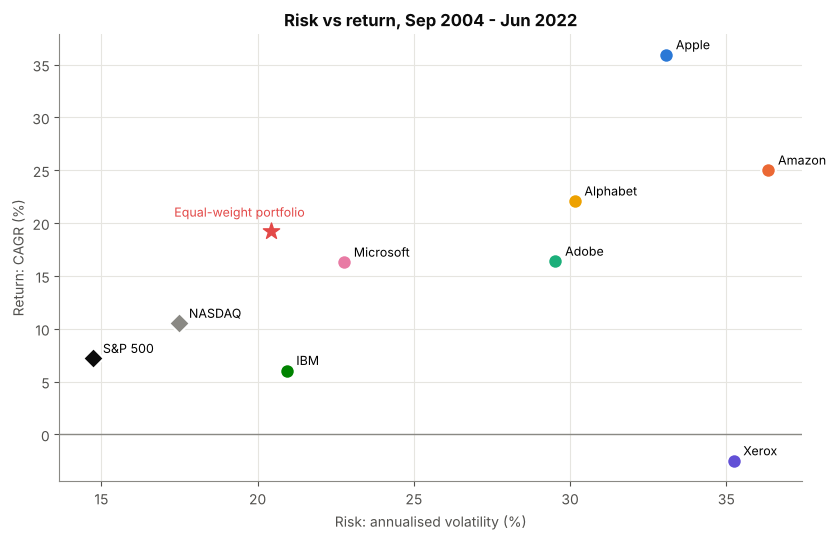

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for c in common.index:
    x, y = common.loc[c, "Volatility"] * 100, common.loc[c, "CAGR"] * 100
    ax.scatter(x, y, s=110, color=colors[c], edgecolor="white", linewidth=1.5, zorder=3,
               marker="D" if c in BENCH else "o")
    ax.annotate(c, (x, y), xytext=(7, 4), textcoords="offset points", fontsize=9)
ax.scatter(pk.Volatility * 100, pk.CAGR * 100, s=150, marker="*", color=RED, zorder=4)
ax.annotate("Equal-weight portfolio", (pk.Volatility * 100, pk.CAGR * 100), xytext=(-70, 10), textcoords="offset points", fontsize=9, color=RED)
ax.axhline(0, color=GREY, linewidth=1)
ax.set_xlabel("Risk: annualised volatility (%)"); ax.set_ylabel("Return: CAGR (%)")
ax.set_title("Risk vs return, Sep 2004 - Jun 2022")
plt.tight_layout()
plt.savefig("figures/02_risk_return.png", dpi=150, bbox_inches="tight")

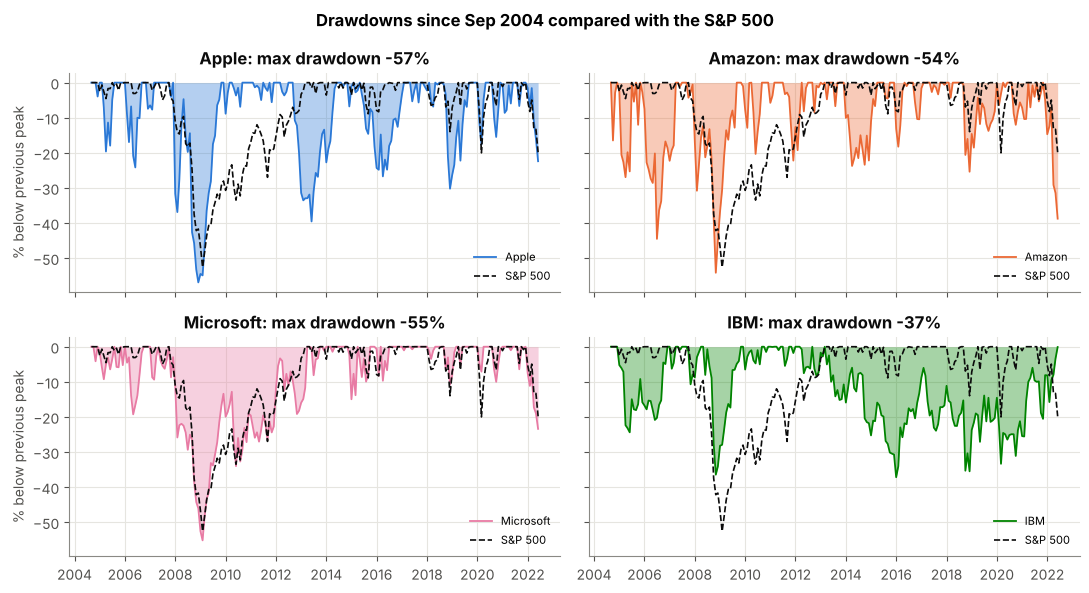

In [13]:
dd = (win / win.cummax() - 1)
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey=True)
for ax, c in zip(axes.flat, ["Apple", "Amazon", "Microsoft", "IBM"]):
    ax.fill_between(dd.index.to_timestamp(), dd[c] * 100, 0, color=colors[c], alpha=0.35, linewidth=0)
    ax.plot(dd.index.to_timestamp(), dd[c] * 100, color=colors[c], linewidth=1.3, label=c)
    ax.plot(dd.index.to_timestamp(), dd["S&P 500"] * 100, color="#0b0b0b", linestyle="--", linewidth=1.2, label="S&P 500")
    ax.set_title(f"{c}: max drawdown {dd[c].min():.0%}")
    ax.legend(loc="lower right", fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("% below previous peak")
fig.suptitle("Drawdowns since Sep 2004 compared with the S&P 500", fontweight="bold")
plt.tight_layout()
plt.savefig("figures/03_drawdowns.png", dpi=150, bbox_inches="tight")

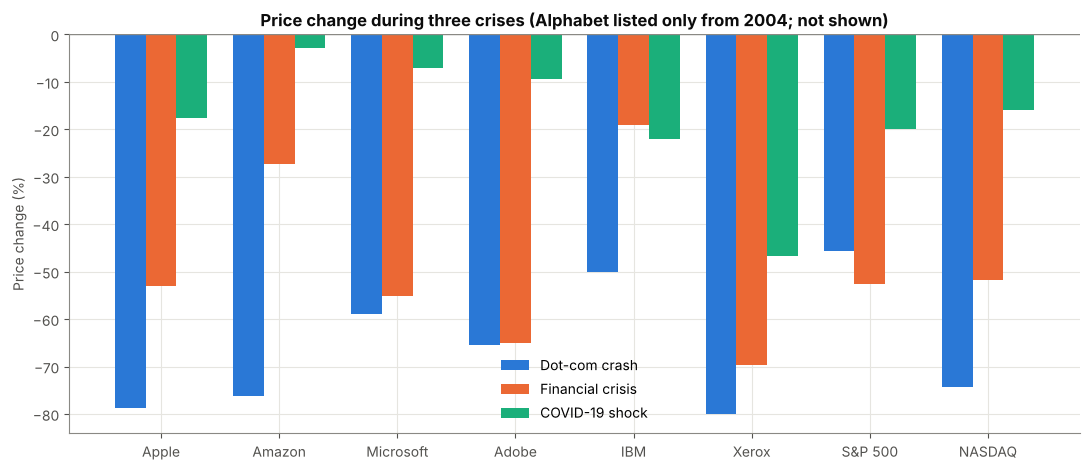

In [14]:
plot_c = crisis.drop(index="2022 sell-off (Dec 2021 - Jun 2022)")[["Apple", "Amazon", "Microsoft", "Adobe", "IBM", "Xerox", "S&P 500", "NASDAQ"]]
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(plot_c.columns)); w = 0.26
for i, (name, row) in enumerate(plot_c.iterrows()):
    ax.bar(x + (i - 1) * w, row.values * 100, width=w, color=[BLUE, ORANGE, AQUA][i], label=name.split(" (")[0])
ax.axhline(0, color=GREY, linewidth=1)
ax.set_xticks(x); ax.set_xticklabels(plot_c.columns)
ax.set_ylabel("Price change (%)")
ax.set_title("Price change during three crises (Alphabet listed only from 2004; not shown)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/04_crisis_performance.png", dpi=150, bbox_inches="tight")

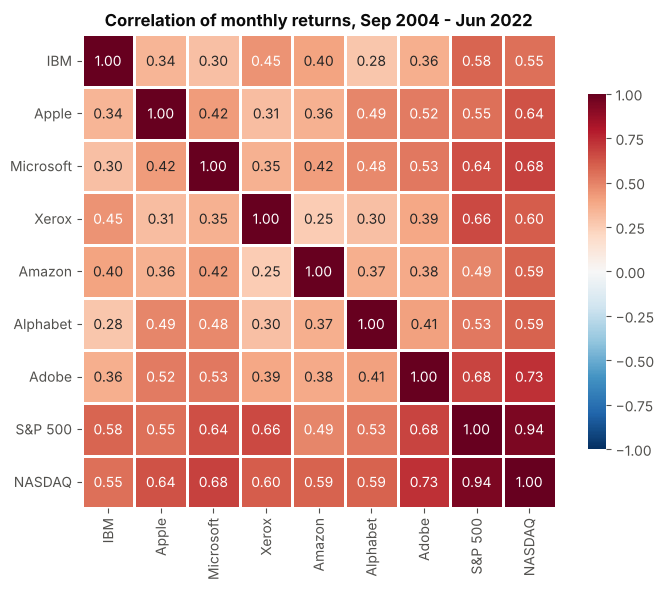

In [15]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            linewidths=1, linecolor="white", cbar_kws={"shrink": 0.75}, ax=ax)
ax.set_title("Correlation of monthly returns, Sep 2004 - Jun 2022")
plt.tight_layout()
plt.savefig("figures/05_correlation.png", dpi=150, bbox_inches="tight")

Years S&P 500 was negative: [1994, 2000, 2001, 2002, 2008, 2011, 2015, 2018]


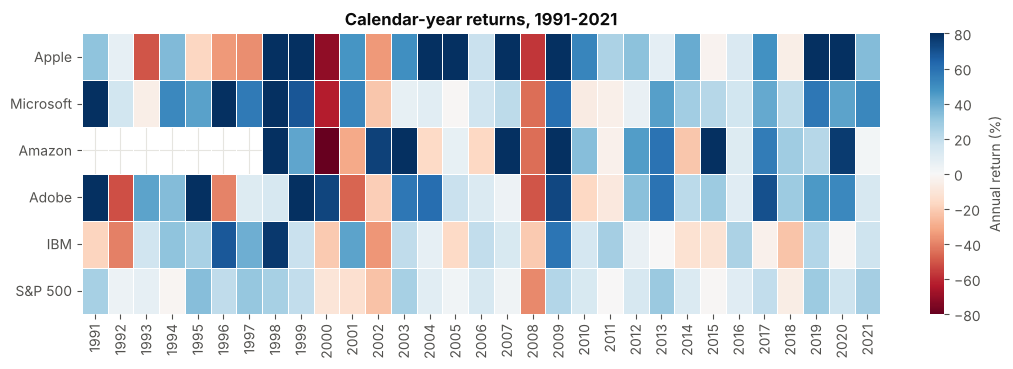

In [16]:
annual = prices.resample("Y").last().pct_change(fill_method=None)
annual.index = annual.index.year
annual = annual.loc[1991:2021, ["Apple", "Microsoft", "Amazon", "Adobe", "IBM", "S&P 500"]]
fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(annual.T * 100, cmap="RdBu", center=0, vmin=-80, vmax=80, cbar_kws={"label": "Annual return (%)"},
            linewidths=0.5, linecolor="white", ax=ax)
ax.set_title("Calendar-year returns, 1991-2021"); ax.set_xlabel("")
plt.tight_layout()
plt.savefig("figures/06_annual_returns_heatmap.png", dpi=150, bbox_inches="tight")
print("Years S&P 500 was negative:", list(annual.index[annual["S&P 500"] < 0]))

## 7. Executive summary (see report for full version)
- Over Sep 2004 – Jun 2022 Apple, Amazon, Microsoft, Alphabet and Adobe all beat the S&P 500 by a wide margin; IBM and Xerox lagged and Xerox lost money.
- The winners carried more risk: higher volatility and deep drawdowns, especially in the dot-com crash.
- Apple gave the best return per unit of risk (1.09), followed by Alphabet (0.73) and Microsoft (0.72).
- An equal-weight mix of the seven stocks reduced volatility well below the typical single stock while keeping strong returns.